<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-/blob/main/Used_Car_Price_Pridection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Used Car Price Prediction & Car Life Assessment Machine Learning Mini Project**

**Project Overview**

The Used Car Price Prediction & Car Life Assessment project analyzes used-car listing data to estimate a vehicle's resale price. It also provides a rule-based estimate of vehicle condition and remaining useful life based on age, distance driven, and ownership history.
This project is implemented entirely in Python using Google Colab. No separate frontend or hardware is required.

> **Important limitation:** The CAR DETAILS FROM CAR DEKHO dataset mainly contains listing details and selling prices. It does not provide verified mechanical inspection labels or actual vehicle retirement dates. Therefore, condition and remaining-life outputs in this version are heuristic estimates, not validated mechanical or safety assessments.
---

**Objectives**

> Explore and clean the used-car dataset.
Understand relationships between car attributes and selling prices.
Prepare numerical and categorical features for machine learning.
Train and compare regression models.
Estimate resale price from car specifications.
Demonstrate transparent, rule-based condition and remaining-life estimates.
Present results with clear tables, charts, and interactive controls in Colab.
---
**Dataset Description**
> Dataset name: CAR DETAILS FROM CAR DEKHO
Common columns include:
Feature	Description
`name`	Car make/model name
`year`	Manufacturing year
`selling_price`	Listed selling price; prediction target
`km_driven`	Distance driven in kilometres
`fuel`	Fuel type
`seller_type`	Seller category
`transmission`	Manual or automatic
`owner`	Previous-owner category
The exact columns may vary by dataset version. The notebook checks the uploaded CSV to determine which columns are available.
---
**Notebook Roadmap**
> Import libraries
Upload the dataset
Load and inspect the CSV
Check data quality
Clean the dataset
Create the car-age feature
Explore the data visually
Select features and target
Split training and testing data
Preprocess numerical and categorical features
Train regression models
Evaluate and compare models
Plot actual versus predicted prices
Predict a sample car's price
Export model results
Select a car and assess price, condition, and estimated remaining life.
---
1. Import Libraries
The project uses Pandas and NumPy for data manipulation, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing, model training, and evaluation. `ipywidgets` supplies interactive controls inside Google Colab.
---
2. Upload the Dataset
Upload the CSV file named CAR DETAILS FROM CAR DEKHO from your computer. The notebook stores the uploaded filename automatically, avoiding errors caused by spaces in Python variable names.
---
3. Load and Inspect the Dataset
Read the CSV into a Pandas DataFrame. Inspect the dataset dimensions, column names, sample rows, data types, and summary statistics. This confirms that the correct file has been loaded.
---
4. Check Data Quality
Review missing values, data types, duplicates, and unusual values. The target column, `selling_price`, must be present and contain valid positive prices for supervised regression.
---
5. Data Cleaning and Preprocessing
Remove duplicate records, normalize column names, convert relevant numeric fields, and remove records with missing or invalid selling prices. Missing feature values are handled later inside the preprocessing pipeline.
---
6. Feature Engineering: Car Age
Calculate car age from the manufacturing year and current year:
Car age = Current year − Manufacturing year
Car age may help explain resale-price differences. It is a derived feature, not a direct measurement of vehicle condition.
---
7. Exploratory Data Analysis (EDA)
Use charts to inspect:
Distribution of selling prices
Selling price versus manufacturing year or car age
Selling price versus kilometres driven
EDA helps reveal patterns, skewed distributions, possible outliers, and relationships between features and price.
---
8. Feature Selection
The target variable is `selling_price`. Input features (`X`) contain available car details, while the target (`y`) contains prices the model learns to predict.
The target must not be included among input features, as that would cause data leakage.
---
9. Training and Testing Split
Divide the dataset into training and testing subsets. The training subset is used to fit the models; the held-out test subset evaluates how well they predict unseen examples.
---
10. Feature Preprocessing
Numerical features use median imputation for missing values. Categorical features use most-frequent-value imputation and one-hot encoding. The preprocessing is fitted within each model pipeline to help avoid leakage from the test set.
---
11. Model Training
The notebook compares three regression algorithms:
Linear Regression: a simple baseline that models linear relationships.
Decision Tree Regressor: learns nonlinear decision rules.
Random Forest Regressor: combines multiple decision trees to improve generalization.
No single model is guaranteed to perform best on every dataset.
---
12. Model Evaluation
Compare trained models using:
MAE (Mean Absolute Error): average absolute prediction error; lower is better.
RMSE (Root Mean Squared Error): penalizes large errors more strongly; lower is better.
R² score: measures explained variation; a higher value is generally better.
Report the values produced by your own run. Do not assume a model is accurate without examining held-out test results.
---
13. Actual vs Predicted Price
Plot actual test-set selling prices against model predictions. Points closer to the diagonal reference line indicate predictions closer to actual values.
---
14. Sample Car Price Prediction
Pass a sample from the held-out test data through the selected model. Display its features, actual listed price, predicted price, and absolute prediction error.
This verifies that the trained pipeline can accept a row with expected features and return a price estimate.
---
15. Export Model Results
Save the model-comparison table as a CSV file. The file can be used in a project report or presentation.
---
16. Interactive Car Assessment
Use Colab dropdowns and sliders to choose a car model, manufacturing year, kilometres driven, and any other available categorical attributes. Clicking Predict Car Details displays the estimated resale price, a heuristic condition category, a score, and an approximate remaining-life value.
What each output means
Estimated resale price: predicted by the trained regression model.
Condition category: assigned by a transparent scoring rule using age, mileage, and an ownership proxy.
Condition score: a heuristic score from 0 to 100, not an inspection result.
Estimated remaining useful life: calculated from assumed service-life and mileage thresholds.
Limitations of condition and lifespan estimates
The standard CAR DETAILS FROM CAR DEKHO dataset does not provide ground-truth mechanical condition or actual end-of-life labels. The condition score and remaining-life figure therefore rely on demonstration assumptions. They do not establish roadworthiness, safety, maintenance quality, or the actual remaining life of an individual car.
For a scientifically validated model, obtain a dataset with inspection reports, maintenance history, component failures, or observed retirement/scrappage outcomes. Until then, label these outputs heuristic estimates.
---
**Conclusion**

This mini project demonstrates a complete tabular machine-learning workflow: data loading, cleaning, exploratory analysis, feature engineering, preprocessing, regression-model training, evaluation, visualization, and prediction.
It also demonstrates how a notebook can combine a learned resale-price prediction with clearly identified rule-based estimates. The distinction between model outputs and heuristic outputs is important for responsible interpretation.
Future Scope
Add more diverse and recent used-car listings.
Tune model hyperparameters using cross-validation.
Analyze model errors by car brand, age, and fuel type.
Add explainability with feature importance or SHAP.
Obtain verified inspection and maintenance data to train a genuine condition model.
Obtain longitudinal vehicle data to model remaining useful life rather than estimating it with fixed thresholds.

---


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
uploaded = files.upload()
file_name = next(iter(uploaded))
print("Uploaded file:", file_name)

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO.csv
Uploaded file: CAR DETAILS FROM CAR DEKHO.csv


In [22]:
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (4340, 8)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Dataset Information and Missing Values

In [23]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing values:


,Missing Values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning and Preprocessing

In [25]:
df.columns = df.columns.str.strip().str.lower()
df = df.drop_duplicates().copy()

for col in ["year", "selling_price", "km_driven"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["selling_price"])
df = df[df["selling_price"] > 0].copy()

print("Dataset after cleaning:", df.shape)


Dataset after cleaning: (3577, 8)


## 5. Feature Engineering

In [27]:
if "year" in df.columns:
    current_year = pd.Timestamp.now().year
    df["car_age"] = (current_year - df["year"]).clip(lower=0)

print("Car age feature created.")


Car age feature created.


## 6. Exploratory Data Analysis

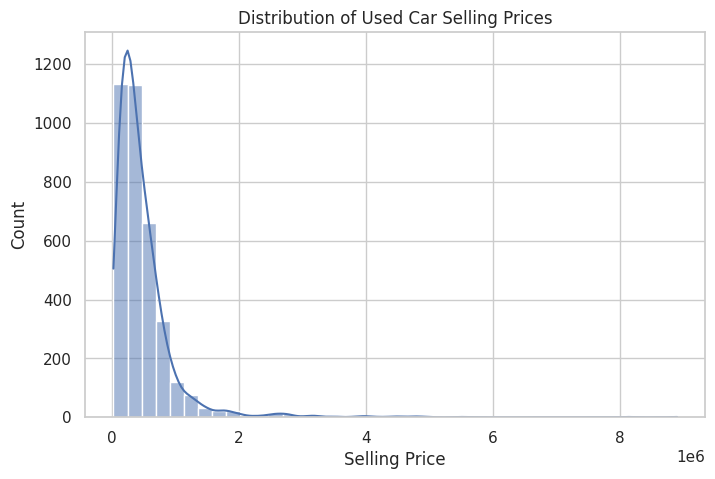

In [28]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="selling_price", bins=40, kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.show()

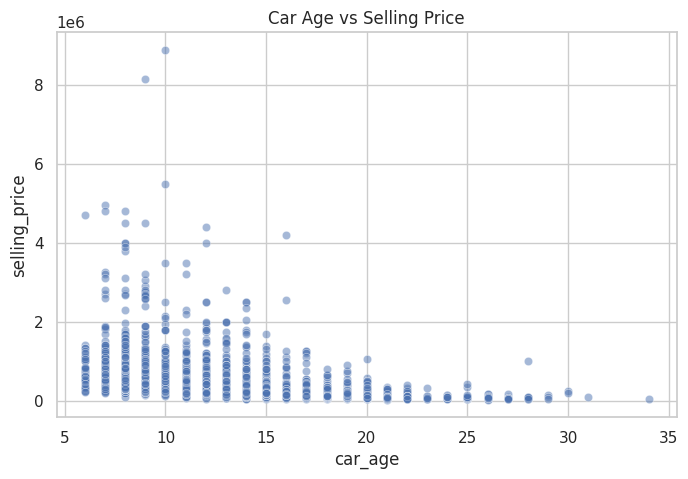

In [29]:
if "car_age" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.5)
    plt.title("Car Age vs Selling Price")
    plt.show()

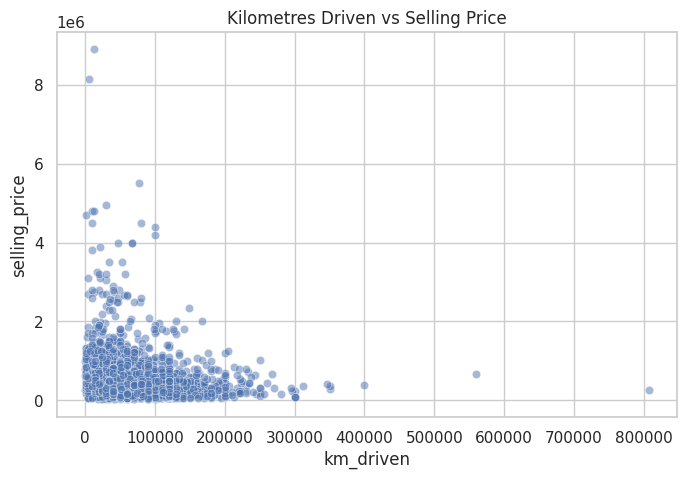

In [30]:
if "km_driven" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.5)
    plt.title("Kilometres Driven vs Selling Price")
    plt.show()

## 7. Feature Selection

In [31]:
target = "selling_price"

X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Use car_age instead of the original manufacturing year
if "year" in X.columns and "car_age" in X.columns:
    X = X.drop(columns=["year"])

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Input features:", X.columns.tolist())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target variable:", target)

Input features: ['name', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'car_age']
Numeric features: ['km_driven', 'car_age']
Categorical features: ['name', 'fuel', 'seller_type', 'transmission', 'owner']
Target variable: selling_price


## 8. Training and Testing Split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2861
Testing records: 716


## 9. Handle Numerical and Categorical Features

In [33]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 10. Model Training

In [34]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        min_samples_leaf=3
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


## 11. Model Evaluation

In [35]:
results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Random Forest,174936.209,408621.329,0.482
1,Decision Tree,189641.254,446149.433,0.382
2,Linear Regression,212414.776,441078.347,0.396


## 12. Compare Model Performance

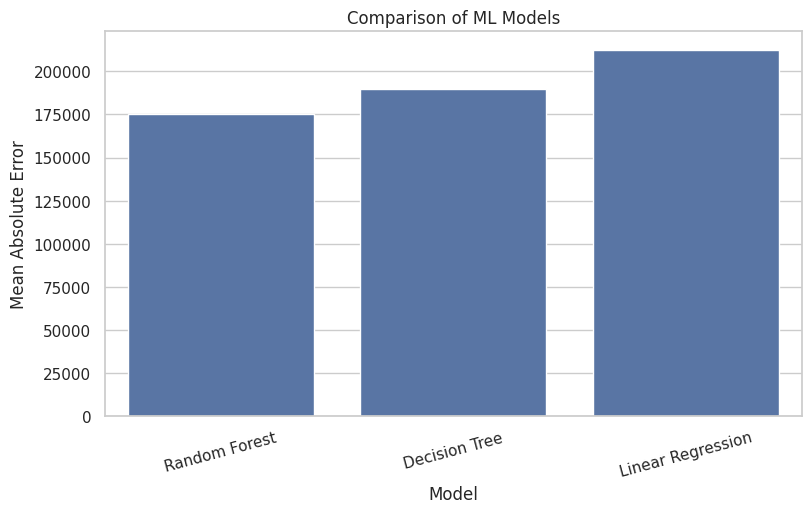

In [36]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Comparison of ML Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.show()

In [37]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on MAE:", best_model_name)

Best model based on MAE: Random Forest


## 13. Actual vs Predicted Prices

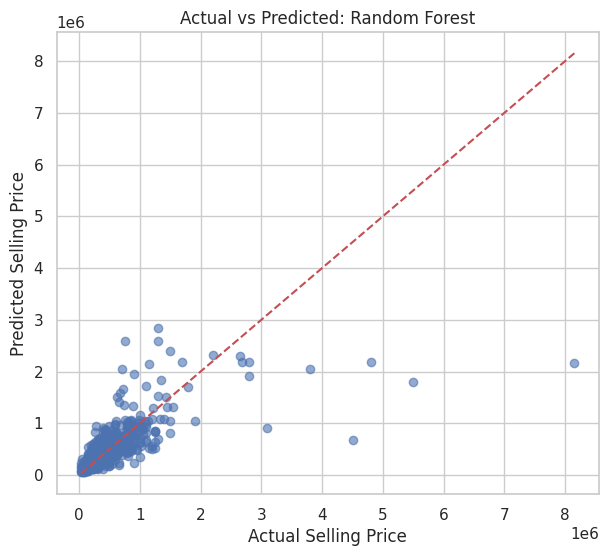

In [38]:
predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.6)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.show()

## 14. Predict a Used Car Price

In [39]:
sample_car = X_test.iloc[[0]]
actual_price = y_test.iloc[0]

predicted_price = best_model.predict(sample_car)[0]

print("Car details:")
display(sample_car)

print(f"Actual price:    {actual_price:,.2f}")
print(f"Predicted price: {predicted_price:,.2f}")
print(f"Absolute error:  {abs(actual_price - predicted_price):,.2f}")

Car details:


,name,km_driven,fuel,seller_type,transmission,owner,car_age
1045,Maruti Eeco 7 Seater Standard BSIV,20000,Petrol,Individual,Manual,First Owner,8


Actual price:    270,000.00
Predicted price: 548,790.08
Absolute error:  278,790.08


## 15. Export Model Comparison Results

In [40]:
results_df.to_csv("car_price_model_results.csv", index=False)

files.download("car_price_model_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Available car models from your dataset
car_models = sorted(df["name"].dropna().unique().tolist())

car_dropdown = widgets.Dropdown(
    options=car_models,
    description="Car model:",
    layout=widgets.Layout(width="500px"),
    style={"description_width": "120px"}
)

year_slider = widgets.IntSlider(
    value=2020, min=2000, max=pd.Timestamp.now().year,
    step=1, description="Manufacturing year:",
    style={"description_width": "150px"},
    layout=widgets.Layout(width="500px")
)

km_slider = widgets.IntSlider(
    value=50000, min=0, max=300000, step=5000,
    description="Kilometres driven:",
    style={"description_width": "150px"},
    layout=widgets.Layout(width="500px")
)

def make_dropdown(column, label):
    if column not in df.columns:
        return None

    values = sorted(df[column].dropna().astype(str).unique().tolist())
    return widgets.Dropdown(
        options=values,
        value=values[0] if values else None,
        description=label,
        style={"description_width": "120px"},
        layout=widgets.Layout(width="500px")
    )

fuel_dropdown = make_dropdown("fuel", "Fuel type:")
transmission_dropdown = make_dropdown("transmission", "Transmission:")
seller_dropdown = make_dropdown("seller_type", "Seller type:")
owner_dropdown = make_dropdown("owner", "Ownership:")

print("Choose your car details below.")
display(car_dropdown, year_slider, km_slider)

for control in [
    fuel_dropdown, transmission_dropdown,
    seller_dropdown, owner_dropdown
]:
    if control is not None:
        display(control)

Choose your car details below.


Dropdown(description='Car model:', layout=Layout(width='500px'), options=('Ambassador CLASSIC 1500 DSL AC', 'A…

IntSlider(value=2020, description='Manufacturing year:', layout=Layout(width='500px'), max=2026, min=2000, sty…

IntSlider(value=50000, description='Kilometres driven:', layout=Layout(width='500px'), max=300000, step=5000, …

Dropdown(description='Fuel type:', layout=Layout(width='500px'), options=('CNG', 'Diesel', 'Electric', 'LPG', …

Dropdown(description='Transmission:', layout=Layout(width='500px'), options=('Automatic', 'Manual'), style=Des…

Dropdown(description='Seller type:', layout=Layout(width='500px'), options=('Dealer', 'Individual', 'Trustmark…

Dropdown(description='Ownership:', layout=Layout(width='500px'), options=('First Owner', 'Fourth & Above Owner…

In [42]:
from IPython.display import display, clear_output
import numpy as np
import pandas as pd
import ipywidgets as widgets

predict_button = widgets.Button(
    description="Predict Car Details",
    button_style="primary",
    icon="check"
)

result_output = widgets.Output()

# Editable assumptions, not learned from this dataset
EXPECTED_SERVICE_LIFE_YEARS = 15
EXPECTED_LIFETIME_KM = 200000
EXPECTED_ANNUAL_KM = 15000

def predict_car_details(_):
    with result_output:
        clear_output(wait=True)

        current_year = pd.Timestamp.now().year
        car_age = max(0, current_year - year_slider.value)
        km = km_slider.value

        # Start with typical values from the training dataset
        row = {}

        for col in X.columns:
            if col in numeric_features:
                row[col] = X[col].median()
            else:
                modes = X[col].mode(dropna=True)
                row[col] = modes.iloc[0] if not modes.empty else "Unknown"

        # Set selected model and user-entered details
        if "name" in X.columns:
            row["name"] = car_dropdown.value

        if "car_age" in X.columns:
            row["car_age"] = car_age

        if "year" in X.columns:
            row["year"] = year_slider.value

        if "km_driven" in X.columns:
            row["km_driven"] = km

        selected_controls = {
            "fuel": fuel_dropdown,
            "transmission": transmission_dropdown,
            "seller_type": seller_dropdown,
            "owner": owner_dropdown
        }

        for col, control in selected_controls.items():
            if col in X.columns and control is not None:
                row[col] = control.value

        input_df = pd.DataFrame([row], columns=X.columns)

        # Existing trained model predicts resale price
        predicted_price = float(best_model.predict(input_df)[0])

        # Transparent heuristic condition score (0 to 100)
        age_score = max(
            0, 1 - car_age / EXPECTED_SERVICE_LIFE_YEARS
        ) * 45

        mileage_score = max(
            0, 1 - km / EXPECTED_LIFETIME_KM
        ) * 40

        owner_score = 15
        if owner_dropdown is not None:
            owner_text = str(owner_dropdown.value).lower()

            if "first" in owner_text:
                owner_score = 15
            elif "second" in owner_text:
                owner_score = 11
            elif "third" in owner_text:
                owner_score = 7
            elif "fourth" in owner_text or "more" in owner_text:
                owner_score = 3

        condition_score = age_score + mileage_score + owner_score

        if condition_score >= 75:
            condition = "Good"
        elif condition_score >= 50:
            condition = "Average"
        else:
            condition = "Poor"

        # Rough remaining-life estimate, based on assumed limits
        life_by_age = max(
            0, EXPECTED_SERVICE_LIFE_YEARS - car_age
        )

        life_by_distance = max(
            0, (EXPECTED_LIFETIME_KM - km) / EXPECTED_ANNUAL_KM
        )

        remaining_life = min(life_by_age, life_by_distance)

        print("CAR ASSESSMENT")
        print("=" * 40)
        print("Selected model:", car_dropdown.value)
        print("Manufacturing year:", year_slider.value)
        print(f"Car age: {car_age} years")
        print(f"Kilometres driven: {km:,} km")
        print(f"\nEstimated resale price: ₹{predicted_price:,.0f}")
        print(f"Condition category: {condition}")
        print(f"Condition score: {condition_score:.1f}/100")
        print(f"Estimated remaining useful life: {remaining_life:.1f} years")

        print("\nIMPORTANT:")
        print("Condition and remaining-life estimates are heuristic only.")
        print("Actual condition requires a mechanical inspection.")
        print("The resale price is an ML prediction, not a guarantee.")

predict_button.on_click(predict_car_details)

display(predict_button, result_output)

Button(button_style='primary', description='Predict Car Details', icon='check', style=ButtonStyle())

Output()